# Credit Scoring : Probabilité de Defaut (PD)

**Dataset** : [Give Me Some Credit](https://www.kaggle.com/c/GiveMeSomeCredit) — Kaggle  
**Objectif** : Predire la probabilite qu'un client fasse defaut sur un credit dans les 2 prochaines annees.

## Resultats obtenus
| Metrique | Score |
|----------|-------|
| AUC | **0.8678** |
| Gini | **0.7357** |
| Dataset | 150 000 clients, 6.7% de clients avec défauts sur leur crédit|

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report, roc_curve
from xgboost import XGBClassifier

## 1. Chargement et exploration

In [19]:
df = pd.read_csv('GiveMeSomeCredit/cs-training.csv', index_col=0)

print('Shape :', df.shape)
print()
print('Distribution de la variable cible :')
print(df['SeriousDlqin2yrs'].value_counts(normalize=True))
print()
df.head()

Shape : (150000, 11)

Distribution de la variable cible :
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64



,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 2. Valeurs manquantes et nettoyage

In [20]:
print(df.isnull().sum()[df.isnull().sum() > 0])
df['MonthlyIncome'].fillna(df['MonthlyIncome'].median(), inplace=True)
df['NumberOfDependents'].fillna(df['NumberOfDependents'].median(), inplace=True)

df['RevolvingUtilizationOfUnsecuredLines'] = df['RevolvingUtilizationOfUnsecuredLines'].clip(0, 1)

df = df[df['age'] > 0]

for col in ['NumberOfTime30-59DaysPastDueNotWorse',
            'NumberOfTime60-89DaysPastDueNotWorse',
            'NumberOfTimes90DaysLate']:
    df[col] = df[col].clip(0, 10)

print('\nShape apres nettoyage :', df.shape)

MonthlyIncome         29731
NumberOfDependents     3924
dtype: int64

Shape apres nettoyage : (149999, 11)


## 3. Modelisation — XGBoost

In [21]:
X = df.drop(columns = ['SeriousDlqin2yrs'] , axis=0)
y = df['SeriousDlqin2yrs']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Train : {X_train.shape[0]} clients | Test : {X_test.shape[0]} clients')

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos

Train : 119999 clients | Test : 30000 clients


In [22]:
model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=spw,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='auc',
    verbosity=0
)

model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'auc'


## 5. Evaluation

In [23]:
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

auc = roc_auc_score(y_test, y_prob)
gini = 2 * auc - 1

print(f'AUC  : {auc:.4f}')
print(f'Gini : {gini:.4f}  (indicateur standard en scoring bancaire)')
print()
print(classification_report(y_test, y_pred, target_names=['Non-defaut', 'Defaut']))

AUC  : 0.8678
Gini : 0.7357  (indicateur standard en scoring bancaire)

              precision    recall  f1-score   support

  Non-defaut       0.98      0.81      0.89     27995
      Defaut       0.22      0.77      0.35      2005

    accuracy                           0.81     30000
   macro avg       0.60      0.79      0.62     30000
weighted avg       0.93      0.81      0.85     30000



## 6. Visualisations

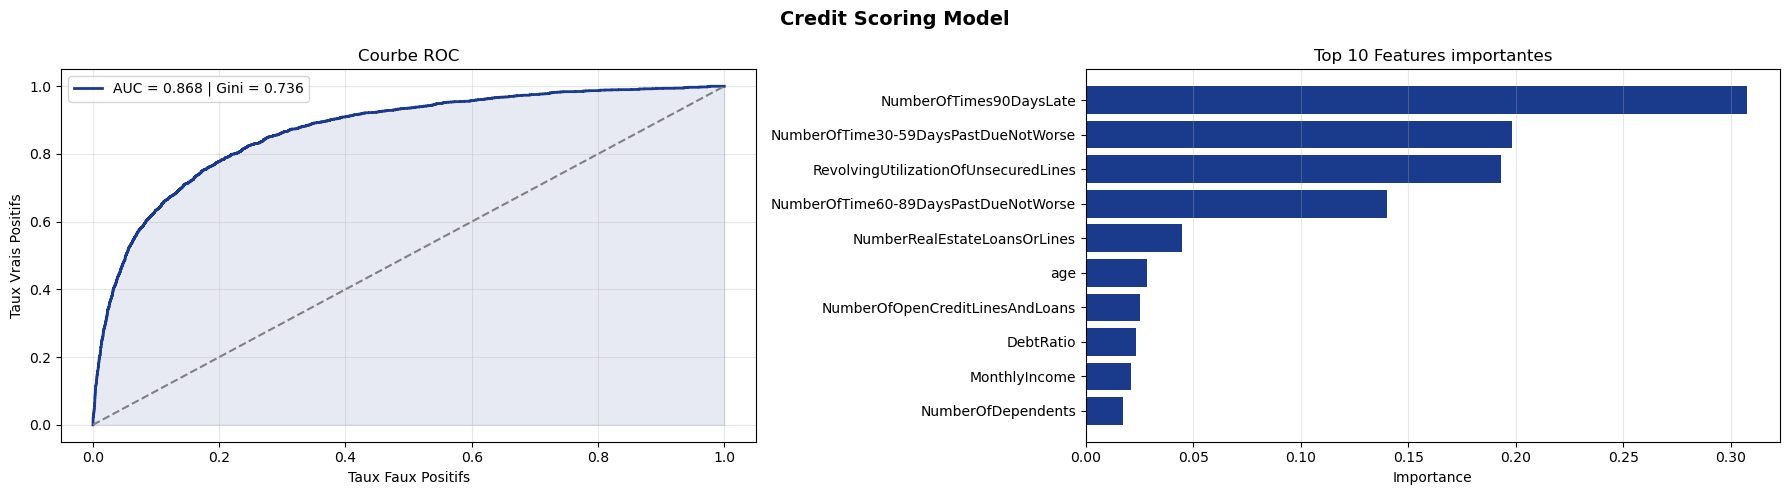

In [25]:
features = [c for c in df.columns if c != 'SeriousDlqin2yrs']
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
fig.suptitle('Credit Scoring Model', fontsize=14, fontweight='bold')


fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[0].plot(fpr, tpr, color='#1A3A8B', lw=2, label=f'AUC = {auc:.3f} | Gini = {gini:.3f}')
axes[0].plot([0,1],[0,1],'--', color='gray')
axes[0].fill_between(fpr, tpr, alpha=0.1, color='#1A3A8B')
axes[0].set_xlabel('Taux Faux Positifs')
axes[0].set_ylabel('Taux Vrais Positifs')
axes[0].set_title('Courbe ROC')
axes[0].legend()
axes[0].grid(alpha=0.3)


fi = pd.Series(model.feature_importances_, index=features).sort_values(ascending=True).tail(10)
axes[1].barh(fi.index, fi.values, color='#1A3A8B')
axes[1].set_title('Top 10 Features importantes')
axes[1].set_xlabel('Importance')
axes[1].grid(alpha=0.3, axis='x')


plt.tight_layout()
plt.savefig('results.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Interpretation

**Feature la plus prédictive** : l’historique de retards
Les retards de paiement passés sont le signal le plus fort pour prédire un défaut futur. Ça confirme la logique des modèles IRB en banque : un client qui a déjà eu du mal à rembourser est statistiquement plus risqué.

**AUC 0.87 | Gini 0.74**
En scoring bancaire, un Gini > 0.50 est considéré comme bon. Ce modèle a donc un score assez correct

**Gestion du déséquilibre**
Le dataset a 93.3% de clients sains et 6.7% de défauts. Un modèle peut obtenir 93% d’accuracy sans rien apprendre. Scale_pos_weight=14 corrige ça en donnant plus de poids aux défauts pendant l’entraînement.